# Predicción del nivel máximo del rio magdalena.

Este es un trabajo experimental en el cual se pondrá a prueba diversos métodos de machine learning para determinar que modelo según cierto criterios es mejor para predecir el nivel máximo del río Magdalena.

El río Magdalena tiene una extensión de 1.540 kilómetros y atraviesa hasta 13 departamentos del territorio colombiano. Su nivel se mide con sensores. *Este dataset fue extraído desde la página oficial de Datos Abiertos Colombia y se puede obtener en el siguiente enlace: [Dataset utilizado](https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Nivel-M-ximo-del-Rio/vfth-yucv/explore/query/SELECT%20%60fechaobservacion%60%2C%20%60valorobservado%60%0AWHERE%20caseless_one_of%28%60codigoestacion%60%2C%20"0025027020"%29/page/filter).*

Tenemos una **serie de tiempo**: un sensor registró el nivel del agua en
distintos horarios. Los datos están en `Nivel_Máximo_del_Rio_20261026.csv` y cubren desde el 4 de octubre de 2004 hasta el 26 de octubre de 2026, de la estación EL BANCO - AUT (código 25027020).

## 1. Importación de librerías y configuración

In [111]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.tree import DecisionTreeRegressor

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")


## 2. Carga del dataset

In [112]:
df_raw = pd.read_csv("Nivel_Máximo_del_Rio_20261026.csv")
df = df_raw.copy()

print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")
df.info()
display(df.head())

Dimensiones: 105,428 filas x 2 columnas
<class 'pandas.DataFrame'>
RangeIndex: 105428 entries, 0 to 105427
Data columns (total 2 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   FechaObservacion  105428 non-null  str  
 1   ValorObservado    105428 non-null  str  
dtypes: str(2)
memory usage: 1.6 MB


,FechaObservacion,ValorObservado
0,2019 Jun 28 10:08:00 PM,"7,44"
1,2015 Mar 11 04:37:00 PM,"4,83"
2,2018 Nov 13 01:42:00 AM,"8,71"
3,2017 Nov 06 03:56:00 PM,"6,66"
4,2017 Nov 21 01:39:00 PM,"5,8"


Nuestras variables se encuentra en el tipo de dato 'string', pasaremos la FechaObservacion a tipo datetime y el ValorObservado cambiaremos el separador "," por "." para convertirlo a tipo float.

In [113]:
df["ValorObservado"] = df["ValorObservado"].str.replace(",", ".")
df["ValorObservado"] = pd.to_numeric(df["ValorObservado"], errors="coerce")

print(f"Datos valor observado con errores al convertir: {df["ValorObservado"].isna().sum()}")

df["FechaObservacion"] = pd.to_datetime(df["FechaObservacion"], format="%Y %b %d %I:%M:%S %p", errors="coerce")

print(f"Datos fecha observada con errores al convertir: {df["FechaObservacion"].isna().sum()}")

df.info()

Datos valor observado con errores al convertir: 0
Datos fecha observada con errores al convertir: 0
<class 'pandas.DataFrame'>
RangeIndex: 105428 entries, 0 to 105427
Data columns (total 2 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   FechaObservacion  105428 non-null  datetime64[us]
 1   ValorObservado    105428 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 1.6 MB


## 3. Inspección inicial
Luego de modificar los tipos de datos se revisarán duplicados y valores faltantes

In [114]:
df_filtrado = df.sort_values("FechaObservacion").reset_index(drop=True)

filas_identicas = df_filtrado.duplicated().sum()

fechas_repetidas = df_filtrado.duplicated(subset=["FechaObservacion"]).sum()

conteo = df_filtrado["FechaObservacion"].value_counts()
conteo = conteo[conteo > 1]

print("Filas idénticas:", filas_identicas)
print("Filas con fecha repetida:", fechas_repetidas)
print("Fechas distintas que se repiten:", len(conteo))

df_filtrado[df_filtrado.duplicated(subset=["FechaObservacion"], keep=False)]

Filas idénticas: 6125
Filas con fecha repetida: 6125
Fechas distintas que se repiten: 5523


,FechaObservacion,ValorObservado
49248,2019-08-28 00:02:00,6.39
49249,2019-08-28 00:02:00,6.39
49250,2019-08-28 00:02:00,6.39
49251,2019-08-28 01:01:00,6.39
49252,2019-08-28 01:01:00,6.39
...,...,...
103717,2026-07-24 23:51:00,4.91
103718,2026-07-24 23:51:00,4.91
103719,2026-07-24 23:51:00,4.91
103720,2026-07-24 23:51:00,4.91


Hay 6125 filas que son copias exactas de otra fila (misma fecha y mismo valor), y están repartidas en 5523 fechas distintas

No se encontró ninguna misma fecha con valores diferentes.

Si se eliminaran las copias, quedarían 105.428 − 6125 = 99.303 filas.

In [115]:
df_unico = df_filtrado.drop_duplicates().reset_index(drop=True)

print("Antes:", df_filtrado.shape[0])
print("Después:", df_unico.shape[0])
print("Eliminadas:", df_filtrado.shape[0] - df_unico.shape[0])
print("Fechas que aún se repiten:", df_unico.duplicated(subset=["FechaObservacion"]).sum(), "\n")
print("Registros con valores nulos:")
df_unico.isnull().sum()

Antes: 105428
Después: 99303
Eliminadas: 6125
Fechas que aún se repiten: 0 

Registros con valores nulos:


FechaObservacion    0
ValorObservado      0
dtype: int64

### 3.1 Resumen de variables 

In [116]:
print("\nResumen de variables:")
display(df_unico.describe(include="all").T)


Resumen de variables:


,count,mean,min,25%,50%,75%,max,std
FechaObservacion,99303,2020-09-12 01:03:32.615993,2004-10-04 22:54:03,2017-12-18 17:19:00,2019-09-13 19:01:00,2024-07-02 23:00:00,2026-10-24 23:45:00,NaN
ValorObservado,99303.0,6.322265,0.0,5.1,6.27,6.96,164.0,9.498909


### ¿Por qué se muestra este rango?

El histograma y el boxplot se enfocan en los niveles **mayores que 0 y hasta 12 m**. Así se amplía la zona donde se concentra la mayoría de las mediciones habituales, aproximadamente entre 4 y 10 m.

El corte de **12 m es exploratorio**: ayuda a visualizar la distribución principal, pero no se ha confirmado como máximo físico del río ni como umbral oficial de calidad de IDEAM.

**Registros fuera del rango mostrado**

- 9.420 mediciones iguales a 0.
- 439 mediciones mayores que 12 m.
- Total: **9.859 registros (9,93 %)**.

Estos registros se excluyen de estos gráficos y del subconjunto `validos`, pero **no se eliminaron de `df_unico`**. Los puntos atípicos que aparecen dentro del rango tampoco se consideran errores automáticamente: el boxplot solo identifica observaciones alejadas de la distribución central.

Mediciones fuera del rango graficado (0 o >12 m): 9,859 (9.93%)


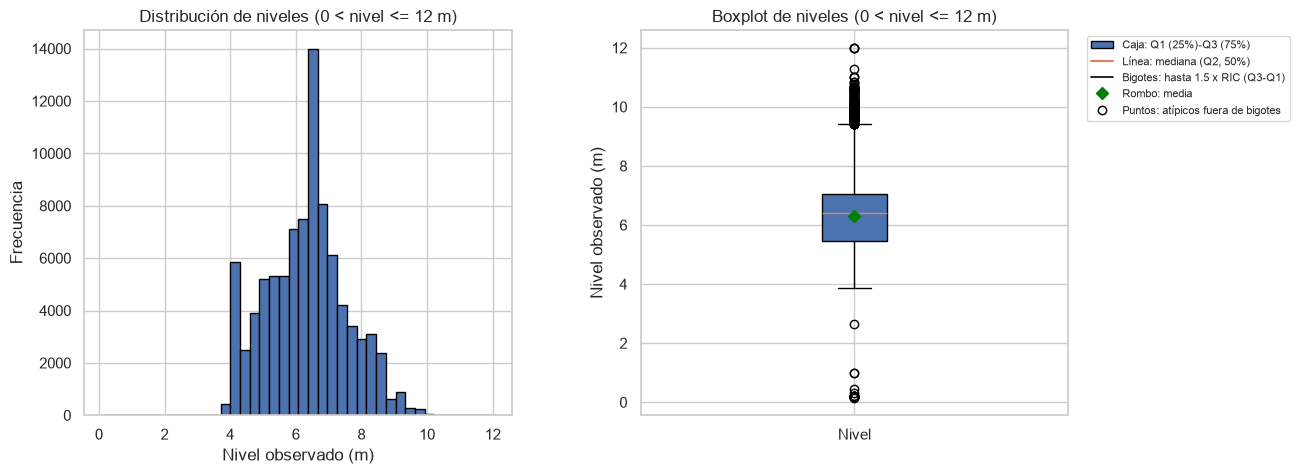

In [117]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

niveles = df_unico["ValorObservado"]
niveles_en_rango = niveles[(niveles > 0) & (niveles <= 12)]
fuera_de_rango = len(niveles) - len(niveles_en_rango)
print(f"Mediciones fuera del rango graficado (0 o >12 m): {fuera_de_rango:,} ({fuera_de_rango / len(niveles):.2%})")

fig, ejes = plt.subplots(1, 2, figsize=(16, 5))

ejes[0].hist(niveles_en_rango, bins=40, edgecolor="black")
ejes[0].set_title("Distribución de niveles (0 < nivel <= 12 m)")
ejes[0].set_xlabel("Nivel observado (m)")
ejes[0].set_ylabel("Frecuencia")

ejes[1].boxplot(
    niveles_en_rango,
    orientation="vertical",
    showmeans=True,
    patch_artist=True,
    meanprops={"marker": "D", "markerfacecolor": "green", "markeredgecolor": "green"},
)
ejes[1].set_title("Boxplot de niveles (0 < nivel <= 12 m)")
ejes[1].set_ylabel("Nivel observado (m)")
ejes[1].set_xticks([1], ["Nivel"])

elementos_leyenda = [
    Patch(facecolor="C0", edgecolor="black", label="Caja: Q1 (25%)-Q3 (75%)"),
    Line2D([0], [0], color="C1", linewidth=1.5, label="Línea: mediana (Q2, 50%)"),
    Line2D([0], [0], color="black", linewidth=1.2, label="Bigotes: hasta 1.5 x RIC (Q3-Q1)"),
    Line2D([0], [0], marker="D", color="green", linestyle="None", label="Rombo: media"),
    Line2D([0], [0], marker="o", markerfacecolor="white", markeredgecolor="black", linestyle="None", label="Puntos: atípicos fuera de bigotes"),
]
ejes[1].legend(handles=elementos_leyenda, loc="upper left", bbox_to_anchor=(1.03, 1), fontsize=8)

fig.subplots_adjust(right=0.74, wspace=0.3)
plt.show()

Se observan valores desde 0 hasta 164 m. Aunque la ficha de IDEAM indica que la unidad es metros, también advierte que los datos son crudos y no han sido validados. Por eso, los extremos requieren revisión antes de clasificarlos como mediciones válidas o errores.

In [118]:
limite = 12

print("Valores iguales a 0:", (df_unico["ValorObservado"] == 0).sum())
print(f"Valores mayores a {limite}:", (df_unico["ValorObservado"] > limite).sum())

ceros = df_unico[df_unico["ValorObservado"] == 0]
print(ceros["FechaObservacion"].min(), ceros["FechaObservacion"].max())

display(df_unico.nlargest(15, "ValorObservado"))

Valores iguales a 0: 9420
Valores mayores a 12: 439
2017-10-07 08:52:00 2025-07-22 04:00:00


,FechaObservacion,ValorObservado
27645,2017-12-30 20:08:00,164.0
24131,2017-12-07 03:22:00,149.0
24507,2017-12-16 04:30:00,149.0
24514,2017-12-16 05:06:00,149.0
24613,2017-12-17 04:30:00,149.0
24619,2017-12-17 05:06:00,149.0
24652,2017-12-17 15:06:00,149.0
24662,2017-12-17 18:00:00,149.0
24704,2017-12-18 03:12:00,149.0
24711,2017-12-18 04:30:00,149.0


In [119]:
anomalos = df_unico[(df_unico["ValorObservado"] == 0) | (df_unico["ValorObservado"] > limite)]

print("Total de valores raros:", len(anomalos))
print(f"Porcentaje del total: {len(anomalos) / len(df_unico):.2%}")

anomalos["FechaObservacion"].dt.year.value_counts().sort_index()

Total de valores raros: 9859
Porcentaje del total: 9.93%


FechaObservacion
2012       1
2017    3192
2018    6653
2024       7
2025       6
Name: count, dtype: int64

In [120]:
valores_mayores_12 = df_unico.loc[
    df_unico["ValorObservado"] > 12,
    ["FechaObservacion", "ValorObservado"],
].copy()
frecuencia_valores_altos = (
    valores_mayores_12["ValorObservado"]
    .value_counts()
    .rename_axis("nivel_m")
    .reset_index(name="registros")
)

ceros_en_crudo = (df_filtrado["ValorObservado"] == 0).sum()
ceros_deduplicados = (df_unico["ValorObservado"] == 0).sum()
ceros_duplicados_eliminados = ceros_en_crudo - ceros_deduplicados

print("Ceros en CSV cargado:", ceros_en_crudo)
print("Ceros tras quitar duplicados exactos:", ceros_deduplicados)
print("Ceros que eran duplicados exactos:", ceros_duplicados_eliminados)
print("Valores >12 m tras quitar duplicados:", len(valores_mayores_12))
display(frecuencia_valores_altos)

Ceros en CSV cargado: 9427
Ceros tras quitar duplicados exactos: 9420
Ceros que eran duplicados exactos: 7
Valores >12 m tras quitar duplicados: 439


,nivel_m,registros
0,149.00,384
1,131.00,26
2,126.00,6
3,13.00,3
4,26.00,3
5,32.00,2
6,136.00,2
7,38.00,2
8,125.00,2
9,76.00,2


### Hallazgos sobre valores sospechosos

**Lo que confirma la fuente:** la ficha oficial de [Nivel Máximo del Río](https://www.datos.gov.co/api/views/vfth-yucv.json) indica que la unidad es metros y define el nivel máximo como el punto más alto registrado durante una hora. También advierte que los datos son crudos, no han sido validados por IDEAM y pueden contener errores de sensor. La ficha no establece 12 m como límite oficial ni define el valor 0 como código de error.

**Lo observado en este archivo:** después de quitar duplicados exactos hay 9.420 ceros y 439 valores mayores a 12 m. Los altos tienen 17 valores distintos: 149 m aparece 384 veces, 131 m 26 veces y 126 m seis veces. Se concentran en 2017 y 2018. La consulta del portal para la estación EL BANCO - AUT identifica esos altos con el sensor `0231` y la unidad `mt`. El patrón repetido es sospechoso, pero por sí solo no demuestra que sean errores.

En el CSV cargado había 9.427 ceros; siete pertenecían a filas duplicadas exactas que se quitaron. Por eso `df_unico` conserva 9.420 ceros. El portal devuelve 9.427 ceros y 439 valores mayores a 12 para la estación en su conjunto, en concordancia con el CSV antes de deduplicar.

**Criterio aplicado al experimento:** `df_unico` se mantiene intacto como referencia. Ambas variantes excluyen los ceros y los historiales con saltos >8 h entre las seis lecturas; una excluye los niveles >12 m y la otra los conserva para comparar el efecto del corte. El límite de 12 m no es oficial y ninguno de estos filtros certifica la calidad oficial de las mediciones.

In [121]:
ceros["FechaObservacion"].dt.to_period("M").value_counts().sort_index()


FechaObservacion
2017-10       3
2017-11      17
2017-12    3121
2018-01    6266
2024-11       1
2024-12       6
2025-03       1
2025-04       1
2025-06       2
2025-07       2
Freq: M, Name: count, dtype: int64

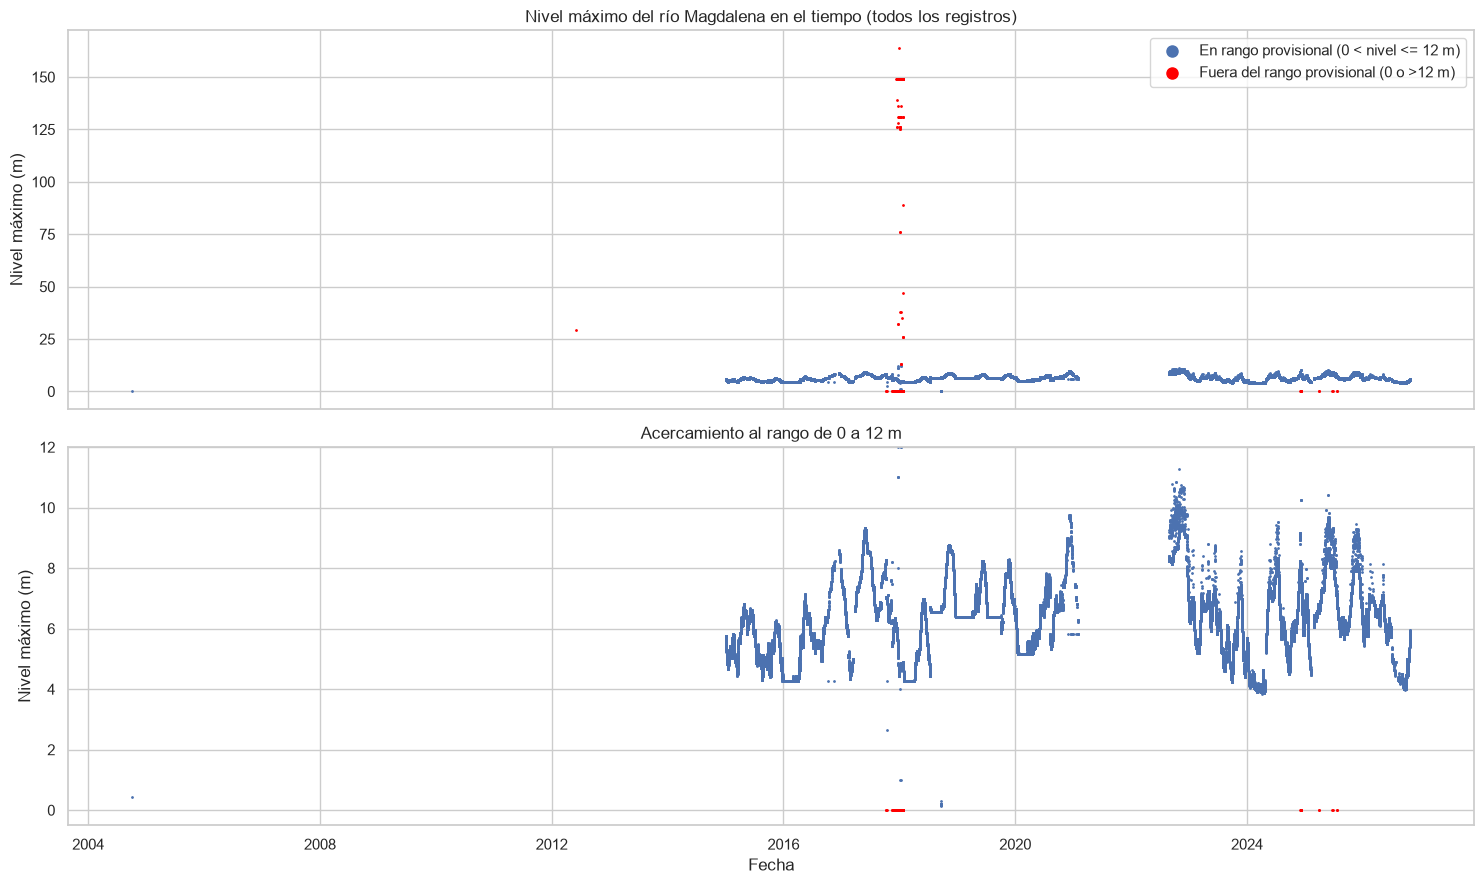

In [122]:
limite = 12
fuera_criterio = (df_unico["ValorObservado"] == 0) | (df_unico["ValorObservado"] > limite)
validos = df_unico[~fuera_criterio]
anomalos = df_unico[fuera_criterio]

fig, ejes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

ejes[0].scatter(validos["FechaObservacion"], validos["ValorObservado"], s=1, label="En rango provisional (0 < nivel <= 12 m)")
ejes[0].scatter(anomalos["FechaObservacion"], anomalos["ValorObservado"], s=1, color="red", label="Fuera del rango provisional (0 o >12 m)")
ejes[0].set_title("Nivel máximo del río Magdalena en el tiempo (todos los registros)")
ejes[0].set_ylabel("Nivel máximo (m)")
ejes[0].legend(markerscale=8)

ejes[1].scatter(validos["FechaObservacion"], validos["ValorObservado"], s=1)
ejes[1].scatter(anomalos["FechaObservacion"], anomalos["ValorObservado"], s=1, color="red")
ejes[1].set_ylim(-0.5, 12)
ejes[1].set_title("Acercamiento al rango de 0 a 12 m")
ejes[1].set_xlabel("Fecha")
ejes[1].set_ylabel("Nivel máximo (m)")

plt.tight_layout()
plt.show()

In [123]:
fechas_validas = validos["FechaObservacion"]

huecos = pd.DataFrame({
    "desde": fechas_validas.shift(1),
    "hasta": fechas_validas,
    "duracion": fechas_validas.diff()
})
huecos = huecos[huecos["duracion"] > pd.Timedelta(days=30)].sort_values("duracion", ascending=False)

display(huecos)

,desde,hasta,duracion
2,2004-10-04 22:54:03,2015-01-01 00:01:00,3740 days 01:06:57
60101,2021-02-02 11:01:00,2022-08-26 21:22:00,570 days 10:21:00


Podemos ver como antes del 2015 prácticamente no existen registro a excepción de 2 valores atípicos, ademas se identifica como existe un falta de registros entre el año 2021 y el año 2022.

Los puntos rojos en 0 están entre finales de 2017 y 2018, con datos válidos mezclados. No es un hueco completo, por eso no sale en la tabla. Hay unos pocos ceros más a finales de 2024 y 2025.
Los valores como 149 y 164 están todos en diciembre de 2017. Se ve una columna de puntos rojos en esa fecha.
Hay subidas y bajadas que se repiten cada año, entre unos 4 y 10 m. Es la estacionalidad que se puede observar ya que el nivel del río depende de la temporadas de lluvia y sequías del año.

## 4. Preparación para modelos

El entrenamiento parte únicamente de `filtrada.csv`, construida con registros deduplicados cuyo nivel cumple `0 < nivel <= 12 m`. Los niveles mayores a 12 m y los ceros no se usan en predictores ni objetivos del modelo. El corte de 12 m y el límite de 8 horas entre lecturas son decisiones exploratorias, no criterios oficiales de calidad del IDEAM.

El archivo contiene una fila por origen, los predictores y los objetivos de máximo observado para cuatro horizontes: 8 horas, 1 día, 3 días y 1 semana. Cada horizonte se entrena y evalúa por separado.

## Variables seleccionadas

Se conserva el grupo que obtuvo el mejor resultado preliminar: seis niveles recientes (`nivel_t` y cinco rezagos) y los cinco intervalos entre esas lecturas, para un total de 11 predictores. Se excluyen las variables cíclicas de mes y hora porque no mejoraron la evaluación preliminar.

## Separación 80/20

Para cada horizonte, los datos de `filtrada.csv` se ordenan por fecha y se toma como inicio de prueba el corte del 80 %. Se eliminan del entrenamiento los orígenes cuya ventana objetivo alcanza el comienzo de prueba, evitando que el entrenamiento use niveles del periodo de prueba. La prueba se reserva para reportar MAE y RMSE.

## 5. Construcción de `filtrada.csv`

Cada origen usa las seis lecturas válidas más recientes, con un intervalo máximo provisional de 8 horas entre lecturas. El objetivo es el máximo observado después del origen en `(t, t + h]`; si no hay lecturas dentro de esa ventana, el objetivo correspondiente queda vacío.

Esta celda genera **un solo archivo**, `filtrada.csv`: excluye siempre ceros y niveles mayores a 12 m, y contiene los 11 predictores seleccionados y cuatro objetivos (8 h, 24 h, 72 h y 168 h).

In [124]:
from pathlib import Path
import pandas as pd
import numpy as np

horizontes_horas = [8, 24, 72, 168]
ruta_filtrada = Path.cwd() / "filtrada.csv"

# 1. Filtrar valores válidos de nivel (0 < nivel <= 12 m)
mascara_modelo = (
    df_unico["FechaObservacion"].notna()
    & df_unico["ValorObservado"].gt(0)
    & df_unico["ValorObservado"].le(12)
)
df_modelo = (
    df_unico.loc[mascara_modelo]
    .sort_values("FechaObservacion")
    .reset_index(drop=True)
    .copy()
)
print("Registros usados (0 < nivel <= 12 m):", len(df_modelo))

fechas = df_modelo["FechaObservacion"]
fechas_ns = fechas.to_numpy(dtype="datetime64[ns]").view("int64")
niveles_array = df_modelo["ValorObservado"].to_numpy(dtype=float)

# 2. Codificar Estacionalidad Anual (Seno y Coseno basados en el día del año)
dia_del_anio = fechas.dt.dayofyear
mes_sin = np.sin(2 * np.pi * dia_del_anio / 365.25)
mes_cos = np.cos(2 * np.pi * dia_del_anio / 365.25)

X = pd.DataFrame(index=df_modelo.index)
X["nivel_t"] = niveles_array
X["mes_sin"] = mes_sin.values
X["mes_cos"] = mes_cos.values

# 3. Construir características del PASADO (Horizontes hacia atrás)
for horizonte in horizontes_horas:
    max_pasado = np.full(len(df_modelo), np.nan, dtype=float)
    duracion_ns = pd.Timedelta(hours=horizonte).value

    for posicion, fecha_ns in enumerate(fechas_ns):
        inicio = np.searchsorted(fechas_ns, fecha_ns - duracion_ns, side="left")
        fin = posicion  # Hasta el momento actual t
        if inicio < fin:
            max_pasado[posicion] = niveles_array[inicio:fin].max()
        else:
            max_pasado[posicion] = niveles_array[posicion]

    X[f"maximo_pasado_ultimas_{horizonte}h"] = max_pasado

historial_completo = X.notna().all(axis=1)
print("Orígenes con historial incompleto:", int((~historial_completo).sum()))

# 4. Construir objetivos del FUTURO (Horizontes hacia adelante)
objetivos = pd.DataFrame(index=df_modelo.index)
resumen_horizontes = []
for horizonte in horizontes_horas:
    objetivo = np.full(len(df_modelo), np.nan, dtype=float)
    duracion_ns = pd.Timedelta(hours=horizonte).value

    for posicion, fecha_ns in enumerate(fechas_ns):
        inicio = np.searchsorted(fechas_ns, fecha_ns, side="right")
        fin = np.searchsorted(fechas_ns, fecha_ns + duracion_ns, side="right")
        if inicio < fin:
            objetivo[posicion] = niveles_array[inicio:fin].max()

    nombre_objetivo = f"maximo_observado_proximas_{horizonte}h"
    objetivos[nombre_objetivo] = objetivo
    resumen_horizontes.append({
        "horizonte_horas": horizonte,
        "muestras": int((historial_completo & objetivos[nombre_objetivo].notna()).sum()),
    })

# 5. Exportar a filtrada.csv (incluyendo nivel_t, mes_sin, mes_cos y picos pasados)
columnas_predictores_pasado = ["nivel_t", "mes_sin", "mes_cos"] + [f"maximo_pasado_ultimas_{h}h" for h in horizontes_horas]
mascara_exportacion = historial_completo & objetivos.notna().any(axis=1)

filtrada = pd.concat(
    [fechas.rename("fecha_origen"), X[columnas_predictores_pasado], objetivos],
    axis=1,
).loc[mascara_exportacion].reset_index(drop=True)

filtrada.to_csv(ruta_filtrada, index=False, date_format="%Y-%m-%d %H:%M:%S")

print("Archivo generado con estacionalidad:", ruta_filtrada)
print("Filas:", len(filtrada))
display(pd.DataFrame(resumen_horizontes))

Registros usados (0 < nivel <= 12 m): 89444
Orígenes con historial incompleto: 0
Archivo generado con estacionalidad: c:\Users\ESTUDIANTE\Downloads\sss\filtrada.csv
Filas: 89436


,horizonte_horas,muestras
0,8,89225
1,24,89380
2,72,89422
3,168,89436


## 6. Preparación y partición temporal

Después de generar `filtrada.csv`, esta celda crea para cada horizonte la partición cronológica 80/20 y purga del entrenamiento los orígenes cuya ventana objetivo alcanza el inicio de prueba. También define los pliegues temporales purgados que reutilizan Ridge, el árbol y Random Forest.

In [125]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.model_selection import TimeSeriesSplit

ruta_filtrada = Path.cwd() / "filtrada.csv"
datos_filtrados = pd.read_csv(ruta_filtrada, parse_dates=["fecha_origen"])

# 1. Crear dinámicamente los deltas de los picos pasados vs nivel actual
for h_pasado in [8, 24, 72, 168]:
    datos_filtrados[f"delta_pasado_{h_pasado}h"] = (
        datos_filtrados["nivel_t"] - datos_filtrados[f"maximo_pasado_ultimas_{h_pasado}h"]
    )

# 2. Definir las columnas predictoras incluyendo nivel, estacionalidad, picos pasados y deltas
columnas_predictores = [
    "nivel_t",
    "mes_sin",
    "mes_cos",
    "maximo_pasado_ultimas_8h",
    "maximo_pasado_ultimas_24h",
    "maximo_pasado_ultimas_72h",
    "maximo_pasado_ultimas_168h",
    "delta_pasado_8h",
    "delta_pasado_24h",
    "delta_pasado_72h",
    "delta_pasado_168h",
]

particiones_por_horizonte = {}
resultados_comparacion = pd.DataFrame(
    columns=["modelo", "horizonte_horas", "muestras_prueba", "MAE_m", "RMSE_m"]
)

horizontes_horas = [8, 24, 72, 168]

# 3. Generación de particiones por horizonte con purga temporal estricta
for horizonte in horizontes_horas:
    columna_objetivo = f"maximo_observado_proximas_{horizonte}h"
    datos = (
        datos_filtrados
        .dropna(subset=[columna_objetivo])
        .sort_values("fecha_origen")
        .reset_index(drop=True)
    )
    posicion_corte = int(len(datos) * 0.8)
    fecha_inicio_prueba = datos.loc[posicion_corte, "fecha_origen"]
    duracion_horizonte = pd.Timedelta(hours=horizonte)
    
    mascara_entrenamiento = (
        (datos["fecha_origen"] < fecha_inicio_prueba)
        & (datos["fecha_origen"] + duracion_horizonte < fecha_inicio_prueba)
    )
    entrenamiento = datos.loc[mascara_entrenamiento].reset_index(drop=True)
    prueba = datos.loc[datos["fecha_origen"] >= fecha_inicio_prueba].reset_index(drop=True)
    
    if entrenamiento.empty or prueba.empty:
        raise ValueError(f"No hay suficientes datos para el horizonte de {horizonte} h.")

    particiones_por_horizonte[horizonte] = {
        "entrenamiento": entrenamiento,
        "prueba": prueba,
        "fecha_inicio_prueba": fecha_inicio_prueba,
    }
    print(
        f"Horizonte {horizonte} h | corte: {fecha_inicio_prueba} | "
        f"entrenamiento: {len(entrenamiento)} | prueba: {len(prueba)} | "
        f"purgadas: {int((datos['fecha_origen'] < fecha_inicio_prueba).sum() - len(entrenamiento))}"
    )

# 4. Función de pliegues temporales con purga para GridSearchCV
def crear_pliegues_temporales(entrenamiento, horizonte, n_splits=3):
    duracion = pd.Timedelta(hours=horizonte)
    pliegues = []
    for indices_entrenamiento, indices_validacion in TimeSeriesSplit(
        n_splits=n_splits
    ).split(entrenamiento):
        inicio_validacion = entrenamiento.iloc[indices_validacion]["fecha_origen"].min()
        fechas_entrenamiento = entrenamiento.iloc[indices_entrenamiento]["fecha_origen"]
        indices_entrenamiento = indices_entrenamiento[
            (fechas_entrenamiento + duracion < inicio_validacion).to_numpy()
        ]
        if len(indices_entrenamiento) == 0:
            raise ValueError(f"Pliegue temporal vacío: horizonte {horizonte} h")
        pliegues.append((indices_entrenamiento, indices_validacion))
    return pliegues

display(datos_filtrados.head())

Horizonte 8 h | corte: 2025-01-25 16:58:00 | entrenamiento: 71366 | prueba: 17845 | purgadas: 14
Horizonte 24 h | corte: 2025-01-25 09:56:00 | entrenamiento: 71459 | prueba: 17876 | purgadas: 45
Horizonte 72 h | corte: 2025-01-25 10:53:00 | entrenamiento: 71396 | prueba: 17885 | purgadas: 141
Horizonte 168 h | corte: 2025-01-25 10:27:00 | entrenamiento: 71221 | prueba: 17888 | purgadas: 327


,fecha_origen,nivel_t,mes_sin,mes_cos,maximo_pasado_ultimas_8h,maximo_pasado_ultimas_24h,maximo_pasado_ultimas_72h,maximo_pasado_ultimas_168h,maximo_observado_proximas_8h,maximo_observado_proximas_24h,maximo_observado_proximas_72h,maximo_observado_proximas_168h,delta_pasado_8h,delta_pasado_24h,delta_pasado_72h,delta_pasado_168h
0,2015-01-01 00:01:00,5.72,0.017202,0.999852,5.72,5.72,5.72,5.72,5.73,5.76,5.76,5.76,0.00,0.00,0.00,0.00
1,2015-01-01 01:11:00,5.72,0.017202,0.999852,5.72,5.72,5.72,5.72,5.73,5.76,5.76,5.76,0.00,0.00,0.00,0.00
2,2015-01-01 02:52:00,5.73,0.017202,0.999852,5.72,5.72,5.72,5.72,5.74,5.76,5.76,5.76,0.01,0.01,0.01,0.01
3,2015-01-01 03:12:00,5.72,0.017202,0.999852,5.73,5.73,5.73,5.73,5.74,5.76,5.76,5.76,-0.01,-0.01,-0.01,-0.01
4,2015-01-01 04:29:00,5.73,0.017202,0.999852,5.73,5.73,5.73,5.73,5.75,5.76,5.76,5.76,0.00,0.00,0.00,0.00


## 7. Líneas base de referencia (Heurísticas de persistencia)

Antes de entrenar modelos de aprendizaje automático, se definen dos líneas base no paramétricas de referencia basadas en persistencia e hidrología:
1. **`ultimo_nivel`**: Asume que el nivel máximo futuro será idéntico a la última medición disponible (`nivel_t`).
2. **`maximo_pasado_mismo_horizonte`**: Asume que el nivel máximo futuro será igual al nivel máximo observado en una ventana pasada de igual duración $(t - h, t]$.

Cualquier modelo de aprendizaje automático (lineal o basado en árboles) debe superar holgadamente estas heurísticas para justificar su complejidad operativa.


=== TABLA CONSOLIDADA FINAL (CON AMBAS LÍNEAS BASE) ===


,modelo,horizonte_horas,muestras_prueba,MAE_m,RMSE_m
0,persistencia_pura,8,17845,0.114439,0.309202
1,persistencia_pasada_simetrica,8,17845,0.14802,0.345794
2,persistencia_pasada_simetrica,24,17876,0.218702,0.393307
3,persistencia_pura,24,17876,0.231536,0.450902
4,persistencia_pasada_simetrica,72,17885,0.26934,0.404056
5,persistencia_pura,72,17885,0.399511,0.611856
6,persistencia_pasada_simetrica,168,17888,0.389495,0.528967
7,persistencia_pura,168,17888,0.565117,0.770675


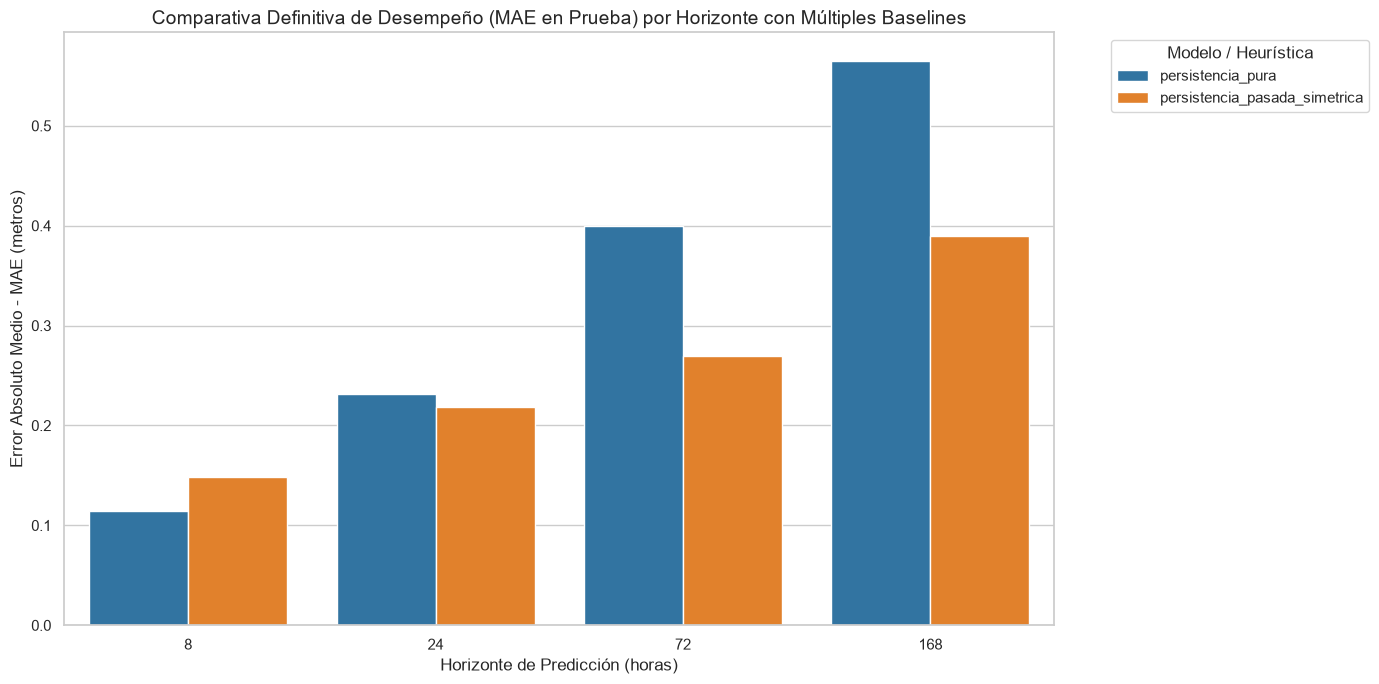

In [126]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

resultados_persistencia = []

for horizonte, particion in particiones_por_horizonte.items():
    prueba = particion["prueba"]
    columna_objetivo = f"maximo_observado_proximas_{horizonte}h"
    col_pasado = f"maximo_pasado_ultimas_{horizonte}h"
    
    real = prueba[columna_objetivo]
    
    # --- Línea Base 1: Persistencia Pura (Nivel actual en t) ---
    prediccion_pura = prueba["nivel_t"]
    resultados_persistencia.append({
        "modelo": "persistencia_pura",
        "horizonte_horas": horizonte,
        "muestras_prueba": len(prueba),
        "MAE_m": mean_absolute_error(real, prediccion_pura),
        "RMSE_m": mean_squared_error(real, prediccion_pura) ** 0.5,
    })
    
    # --- Línea Base 2: Persistencia Histórica Pasada (El pico del equivalente pasado) ---
    prediccion_pasada = prueba[col_pasado]
    resultados_persistencia.append({
        "modelo": "persistencia_pasada_simetrica",
        "horizonte_horas": horizonte,
        "muestras_prueba": len(prueba),
        "MAE_m": mean_absolute_error(real, prediccion_pasada),
        "RMSE_m": mean_squared_error(real, prediccion_pasada) ** 0.5,
    })

resultados_persistencia = pd.DataFrame(resultados_persistencia)

# Agregar las líneas base a la tabla global de comparación de modelos
try:
    # Filtramos para evitar duplicados si se corre varias veces
    modelos_actuales = resultados_comparacion[
        ~resultados_comparacion["modelo"].isin(["persistencia_pura", "persistencia_pasada_simetrica"])
    ]
    resultados_comparacion = pd.concat(
        [modelos_actuales, resultados_persistencia],
        ignore_index=True
    )
except NameError:
    resultados_comparacion = resultados_persistencia

# Tabla consolidada ordenada por horizonte y desempeño (menor MAE)
tabla_final = resultados_comparacion.sort_values(
    ["horizonte_horas", "MAE_m"]
).reset_index(drop=True)

print("=== TABLA CONSOLIDADA FINAL (CON AMBAS LÍNEAS BASE) ===")
display(tabla_final)

# Gráfico comparativo definitivo
plt.figure(figsize=(14, 7))
sns.barplot(
    data=tabla_final,
    x="horizonte_horas",
    y="MAE_m",
    hue="modelo",
    palette="tab10",
)
plt.title("Comparativa Definitiva de Desempeño (MAE en Prueba) por Horizonte con Múltiples Baselines", fontsize=14)
plt.xlabel("Horizonte de Predicción (horas)", fontsize=12)
plt.ylabel("Error Absoluto Medio - MAE (metros)", fontsize=12)
plt.legend(title="Modelo / Heurística", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 8. Regresión lineal regularizada (Ridge)

### 8.1 Modelo inicial de Ridge

Se implementa una regresión lineal con regularización $L_2$ (Ridge). Para garantizar que las variables con diferentes escalas y unidades (niveles en metros vs. intervalos en horas) reciban una penalización equitativa, se integra un `StandardScaler` dentro de un `Pipeline` de scikit-learn.

En esta etapa inicial, se ajusta el modelo con su hiperparámetro de penalización por defecto ($\\alpha = 1.0$) y con intercepto (`fit_intercept = True`) para cada uno de los cuatro horizontes de tiempo, evaluando su desempeño directamente en la partición independiente de prueba (20 %).


In [127]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

resultados_ridge_inicial = []
modelos_ridge_iniciales = {}

for horizonte, particion in particiones_por_horizonte.items():
    entrenamiento = particion["entrenamiento"].copy()
    prueba = particion["prueba"].copy()
    
    col_objetivo_original = f"maximo_observado_proximas_{horizonte}h"
    
    # 1. Creamos variables de velocidad/delta basadas en los picos pasados vs nivel actual
    for h_pasado in [8, 24, 72, 168]:
        entrenamiento[f"delta_pasado_{h_pasado}h"] = entrenamiento["nivel_t"] - entrenamiento[f"maximo_pasado_ultimas_{h_pasado}h"]
        prueba[f"delta_pasado_{h_pasado}h"] = prueba["nivel_t"] - prueba[f"maximo_pasado_ultimas_{h_pasado}h"]

    # Definimos los predictores incluyendo nivel actual, estacionalidad, picos pasados y deltas
    predictores_pasados_delta = [
        "nivel_t",
        "mes_sin",
        "mes_cos",
        "maximo_pasado_ultimas_8h",
        "maximo_pasado_ultimas_24h",
        "maximo_pasado_ultimas_72h",
        "maximo_pasado_ultimas_168h",
        "delta_pasado_8h",
        "delta_pasado_24h",
        "delta_pasado_72h",
        "delta_pasado_168h",
    ]

    # 2. Transformamos el objetivo a DELTA (Máximo futuro - Nivel actual en t)
    y_entrenamiento_delta = entrenamiento[col_objetivo_original] - entrenamiento["nivel_t"]
    y_prueba_real = prueba[col_objetivo_original] # Valor real en metros para evaluar el MAE final

    modelo = Pipeline([
        ("escalador", StandardScaler()),
        ("ridge", Ridge(alpha=1.0, fit_intercept=True, random_state=42)),
    ])
    
    # 3. Entrenamos utilizando los nuevos predictores y el objetivo en delta
    modelo.fit(entrenamiento[predictores_pasados_delta], y_entrenamiento_delta)
    
    # 4. Predecimos el delta y lo SUMAMOS al nivel_t actual de la prueba para volver a metros
    prediccion_delta = modelo.predict(prueba[predictores_pasados_delta])
    prediccion_nivel = prueba["nivel_t"] + prediccion_delta
    
    modelos_ridge_iniciales[horizonte] = modelo

    resultados_ridge_inicial.append({
        "modelo": "ridge_inicial_pasado_delta",
        "horizonte_horas": horizonte,
        "muestras_prueba": len(prueba),
        "MAE_m": mean_absolute_error(y_prueba_real, prediccion_nivel),
        "RMSE_m": mean_squared_error(y_prueba_real, prediccion_nivel) ** 0.5,
    })

resultados_ridge_inicial = pd.DataFrame(resultados_ridge_inicial)
display(resultados_ridge_inicial)

resultados_comparacion = pd.concat(
    [
        resultados_comparacion,
        resultados_ridge_inicial[["modelo", "horizonte_horas", "muestras_prueba", "MAE_m", "RMSE_m"]],
    ],
    ignore_index=True,
)
display(resultados_comparacion.sort_values(["horizonte_horas", "MAE_m"]))

,modelo,horizonte_horas,muestras_prueba,MAE_m,RMSE_m
0,ridge_inicial_pasado_delta,8,17845,0.126933,0.271789
1,ridge_inicial_pasado_delta,24,17876,0.203525,0.335592
2,ridge_inicial_pasado_delta,72,17885,0.275095,0.382877
3,ridge_inicial_pasado_delta,168,17888,0.343274,0.444641


,modelo,horizonte_horas,muestras_prueba,MAE_m,RMSE_m
0,persistencia_pura,8,17845,0.114439,0.309202
8,ridge_inicial_pasado_delta,8,17845,0.126933,0.271789
1,persistencia_pasada_simetrica,8,17845,0.14802,0.345794
9,ridge_inicial_pasado_delta,24,17876,0.203525,0.335592
3,persistencia_pasada_simetrica,24,17876,0.218702,0.393307
2,persistencia_pura,24,17876,0.231536,0.450902
5,persistencia_pasada_simetrica,72,17885,0.26934,0.404056
10,ridge_inicial_pasado_delta,72,17885,0.275095,0.382877
4,persistencia_pura,72,17885,0.399511,0.611856
11,ridge_inicial_pasado_delta,168,17888,0.343274,0.444641


### 8.2 Búsqueda de hiperparámetros de Ridge (Fase Coarse - GridSearchCV)

Siguiendo la estrategia **Coarse-to-Fine**, en esta primera etapa se realiza una exploración amplia (*coarse*) sobre el pipeline de Ridge evaluando **58 combinaciones por horizonte**:
- `ridge__alpha`: 29 valores en escala logarítmica continua cubriendo 14 órdenes de magnitud entre $10^{-7}$ y $10^{7}$ (`np.logspace(-7, 7, 29)`).
- `ridge__fit_intercept`: `[True, False]`.

La validación cruzada utiliza los tres pliegues temporales purgados (`crear_pliegues_temporales`). Esta búsqueda identifica de forma global la escala de regularización óptima para cada horizonte. Posteriormente, los resultados permitirán acotar una búsqueda fina (*fine*) en el rango más prometedor.


,horizonte_horas,alpha,fit_intercept,MAE_CV_m
57,8,1.000000e+07,False,0.058979
55,8,3.162278e+06,False,0.059085
53,8,1.000000e+06,False,0.059760
51,8,3.162278e+05,False,0.062072
56,8,1.000000e+07,True,0.062256
115,24,1.000000e+07,False,0.126417
113,24,3.162278e+06,False,0.126475
111,24,1.000000e+06,False,0.127211
109,24,3.162278e+05,False,0.129668
114,24,1.000000e+07,True,0.129708


,modelo,horizonte_horas,alpha,fit_intercept,muestras_prueba,MAE_CV_m,MAE_prueba_m,RMSE_prueba_m
0,ridge_ajustado_pasado_delta,8,1.000000e+07,False,17845,0.058979,0.114112,0.307988
1,ridge_ajustado_pasado_delta,24,1.000000e+07,False,17876,0.126417,0.230167,0.447551
2,ridge_ajustado_pasado_delta,72,3.162278e+03,True,17885,0.236802,0.275930,0.383110
3,ridge_ajustado_pasado_delta,168,1.000000e+04,True,17888,0.377389,0.345988,0.445742


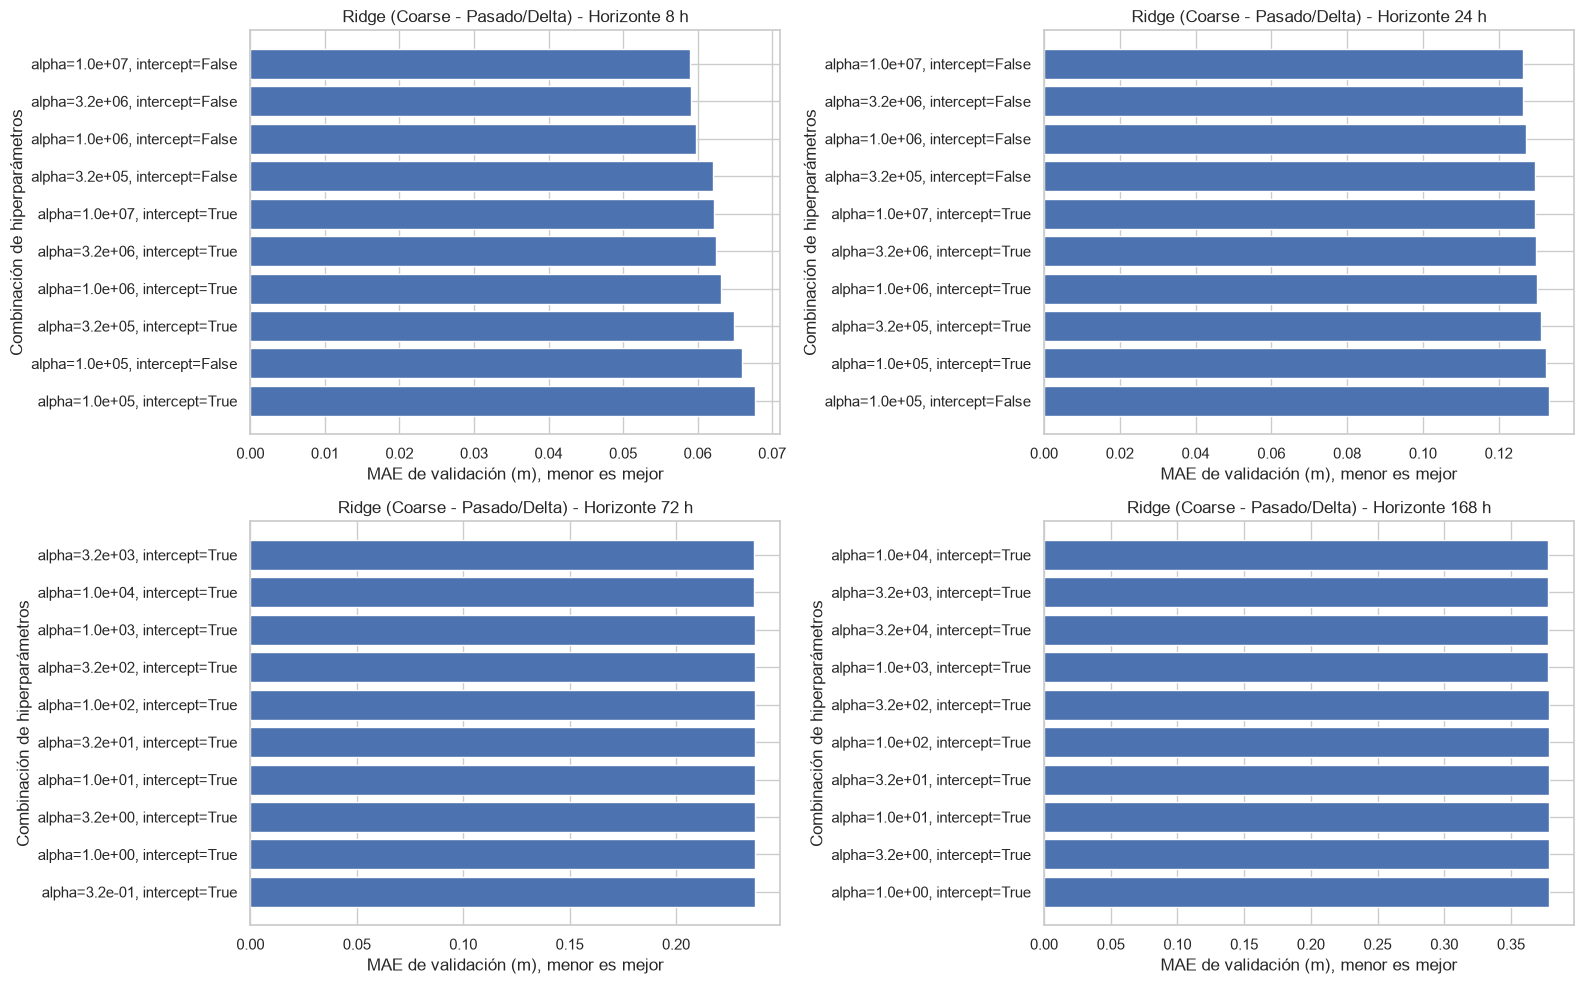

,modelo,horizonte_horas,muestras_prueba,MAE_m,RMSE_m
12,ridge_ajustado_pasado_delta,8,17845,0.114112,0.307988
0,persistencia_pura,8,17845,0.114439,0.309202
8,ridge_inicial_pasado_delta,8,17845,0.126933,0.271789
1,persistencia_pasada_simetrica,8,17845,0.14802,0.345794
9,ridge_inicial_pasado_delta,24,17876,0.203525,0.335592
3,persistencia_pasada_simetrica,24,17876,0.218702,0.393307
13,ridge_ajustado_pasado_delta,24,17876,0.230167,0.447551
2,persistencia_pura,24,17876,0.231536,0.450902
5,persistencia_pasada_simetrica,72,17885,0.26934,0.404056
10,ridge_inicial_pasado_delta,72,17885,0.275095,0.382877


In [128]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

pipeline_ridge = Pipeline([
    ("escalador", StandardScaler()),
    ("ridge", Ridge(random_state=42)),
])

parametros_ridge = {
    "ridge__alpha": np.logspace(-7, 7, 29),
    "ridge__fit_intercept": [True, False],
}

resultados_busqueda_ridge = []
resultados_ridge_ajustado = []
modelos_ridge_ajustados = {}

for horizonte, particion in particiones_por_horizonte.items():
    entrenamiento = particion["entrenamiento"].copy()
    prueba = particion["prueba"].copy()
    columna_objetivo = f"maximo_observado_proximas_{horizonte}h"
    
    # 1. Creamos variables de velocidad/delta basadas en los picos pasados vs nivel actual
    for h_pasado in [8, 24, 72, 168]:
        entrenamiento[f"delta_pasado_{h_pasado}h"] = entrenamiento["nivel_t"] - entrenamiento[f"maximo_pasado_ultimas_{h_pasado}h"]
        prueba[f"delta_pasado_{h_pasado}h"] = prueba["nivel_t"] - prueba[f"maximo_pasado_ultimas_{h_pasado}h"]

    # Definimos los predictores incluyendo nivel actual, estacionalidad, horizontes pasados y deltas
    predictores_pasados_delta = [
        "nivel_t",
        "mes_sin",
        "mes_cos",
        "maximo_pasado_ultimas_8h",
        "maximo_pasado_ultimas_24h",
        "maximo_pasado_ultimas_72h",
        "maximo_pasado_ultimas_168h",
        "delta_pasado_8h",
        "delta_pasado_24h",
        "delta_pasado_72h",
        "delta_pasado_168h",
    ]

    # 2. Transformamos el objetivo de entrenamiento a DELTA (Máximo futuro - Nivel actual en t)
    y_entrenamiento_delta = entrenamiento[columna_objetivo] - entrenamiento["nivel_t"]
    y_prueba_real = prueba[columna_objetivo]  # El valor real en metros para evaluar el MAE final

    busqueda = GridSearchCV(
        pipeline_ridge,
        param_grid=parametros_ridge,
        scoring="neg_mean_absolute_error",
        cv=crear_pliegues_temporales(entrenamiento, horizonte),
        n_jobs=-1,
    )
    
    # 3. Ajustamos el GridSearch usando los predictores completos y el objetivo en delta
    busqueda.fit(entrenamiento[predictores_pasados_delta], y_entrenamiento_delta)
    
    modelo = busqueda.best_estimator_
    modelos_ridge_ajustados[horizonte] = modelo

    # 4. Predecimos el delta y lo SUMAMOS al nivel_t actual de la prueba para volver a metros
    prediccion_delta = modelo.predict(prueba[predictores_pasados_delta])
    prediccion_nivel = prueba["nivel_t"] + prediccion_delta
    
    real = y_prueba_real

    for parametros, mae_cv in zip(
        busqueda.cv_results_["params"], -busqueda.cv_results_["mean_test_score"]
    ):
        resultados_busqueda_ridge.append({
            "horizonte_horas": horizonte,
            "alpha": parametros["ridge__alpha"],
            "fit_intercept": parametros["ridge__fit_intercept"],
            "MAE_CV_m": mae_cv,
        })

    resultados_ridge_ajustado.append({
        "modelo": "ridge_ajustado_pasado_delta",
        "horizonte_horas": horizonte,
        "alpha": busqueda.best_params_["ridge__alpha"],
        "fit_intercept": busqueda.best_params_["ridge__fit_intercept"],
        "muestras_prueba": len(prueba),
        "MAE_CV_m": -busqueda.best_score_,
        "MAE_prueba_m": mean_absolute_error(real, prediccion_nivel),
        "RMSE_prueba_m": mean_squared_error(real, prediccion_nivel) ** 0.5,
    })

resultados_busqueda_ridge = pd.DataFrame(resultados_busqueda_ridge)
resultados_ridge_ajustado = pd.DataFrame(resultados_ridge_ajustado)

configuraciones_ridge_top = resultados_busqueda_ridge.copy()
configuraciones_ridge_top["configuracion"] = configuraciones_ridge_top.apply(
    lambda fila: f"alpha={fila['alpha']:.1e}, intercept={fila['fit_intercept']}",
    axis=1,
)

display(
    resultados_busqueda_ridge.sort_values(
        ["horizonte_horas", "MAE_CV_m"]
    ).groupby("horizonte_horas").head(5)
)
display(resultados_ridge_ajustado)

# Gráficas de validación
fig, ejes = plt.subplots(2, 2, figsize=(16, 10))
for eje, (horizonte, candidatos) in zip(
    ejes.flat, configuraciones_ridge_top.groupby("horizonte_horas")
):
    mejores = candidatos.nsmallest(10, "MAE_CV_m").sort_values("MAE_CV_m")
    eje.barh(mejores["configuracion"], mejores["MAE_CV_m"])
    eje.invert_yaxis()
    eje.set_title(f"Ridge (Coarse - Pasado/Delta) - Horizonte {horizonte} h")
    eje.set_xlabel("MAE de validación (m), menor es mejor")
    eje.set_ylabel("Combinación de hiperparámetros")

fig.tight_layout()
plt.show()

# Consolidación final
resultados_comparacion = pd.concat(
    [
        resultados_comparacion,
        resultados_ridge_ajustado.rename(columns={
            "MAE_prueba_m": "MAE_m",
            "RMSE_prueba_m": "RMSE_m",
        })[["modelo", "horizonte_horas", "muestras_prueba", "MAE_m", "RMSE_m"]],
    ],
    ignore_index=True,
)
display(resultados_comparacion.sort_values(["horizonte_horas", "MAE_m"]))

## 9. Árbol de decisión (Decision Tree)

### 9.1 Modelo inicial de Árbol de decisión

Se entrena un árbol de decisión individual (`DecisionTreeRegressor`) para modelar relaciones no lineales e interacciones complejas entre los niveles observados y los intervalos transcurridos.

Como configuración inicial se establecen restricciones conservadoras para mitigar el sobreajuste propio de árboles sin podar:
- `max_depth = 6` (profundidad máxima)
- `min_samples_leaf = 20` (mínimo de muestras por nodo terminal)
- `random_state = 42`

El modelo inicial se evalúa en el 20 % de prueba para cada uno de los cuatro horizontes temporales.


In [129]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

resultados_arbol_inicial = []
modelos_arbol_iniciales = {}

for horizonte, particion in particiones_por_horizonte.items():
    entrenamiento = particion["entrenamiento"].copy()
    prueba = particion["prueba"].copy()
    col_objetivo_original = f"maximo_observado_proximas_{horizonte}h"

    # 1. Creamos variables de velocidad/delta basadas en los picos pasados vs nivel actual
    for h_pasado in [8, 24, 72, 168]:
        entrenamiento[f"delta_pasado_{h_pasado}h"] = entrenamiento["nivel_t"] - entrenamiento[f"maximo_pasado_ultimas_{h_pasado}h"]
        prueba[f"delta_pasado_{h_pasado}h"] = prueba["nivel_t"] - prueba[f"maximo_pasado_ultimas_{h_pasado}h"]

    # Definimos los predictores completos
    predictores_completos = [
        "nivel_t",
        "mes_sin",
        "mes_cos",
        "maximo_pasado_ultimas_8h",
        "maximo_pasado_ultimas_24h",
        "maximo_pasado_ultimas_72h",
        "maximo_pasado_ultimas_168h",
        "delta_pasado_8h",
        "delta_pasado_24h",
        "delta_pasado_72h",
        "delta_pasado_168h",
    ]

    # 2. Transformamos el objetivo a DELTA (Máximo futuro - Nivel actual en t)
    y_entrenamiento_delta = entrenamiento[col_objetivo_original] - entrenamiento["nivel_t"]
    y_prueba_real = prueba[col_objetivo_original]

    modelo = DecisionTreeRegressor(
        max_depth=6,
        min_samples_leaf=20,
        random_state=42,
    )
    
    # 3. Entrenamos con los predictores completos y el objetivo en delta
    modelo.fit(entrenamiento[predictores_completos], y_entrenamiento_delta)
    
    # 4. Predecimos el delta y lo SUMAMOS al nivel_t actual de la prueba para volver a metros
    prediccion_delta = modelo.predict(prueba[predictores_completos])
    prediccion_nivel = prueba["nivel_t"] + prediccion_delta
    
    modelos_arbol_iniciales[horizonte] = modelo

    resultados_arbol_inicial.append({
        "modelo": "arbol_decision_inicial_delta",
        "horizonte_horas": horizonte,
        "muestras_prueba": len(prueba),
        "MAE_m": mean_absolute_error(y_prueba_real, prediccion_nivel),
        "RMSE_m": mean_squared_error(y_prueba_real, prediccion_nivel) ** 0.5,
    })

resultados_arbol_inicial = pd.DataFrame(resultados_arbol_inicial)
display(resultados_arbol_inicial)

resultados_comparacion = pd.concat(
    [
        resultados_comparacion,
        resultados_arbol_inicial[["modelo", "horizonte_horas", "muestras_prueba", "MAE_m", "RMSE_m"]],
    ],
    ignore_index=True,
)
display(resultados_comparacion.sort_values(["horizonte_horas", "MAE_m"]))

,modelo,horizonte_horas,muestras_prueba,MAE_m,RMSE_m
0,arbol_decision_inicial_delta,8,17845,0.131664,0.288915
1,arbol_decision_inicial_delta,24,17876,0.198973,0.363703
2,arbol_decision_inicial_delta,72,17885,0.227082,0.357222
3,arbol_decision_inicial_delta,168,17888,0.358874,0.494768


,modelo,horizonte_horas,muestras_prueba,MAE_m,RMSE_m
12,ridge_ajustado_pasado_delta,8,17845,0.114112,0.307988
0,persistencia_pura,8,17845,0.114439,0.309202
8,ridge_inicial_pasado_delta,8,17845,0.126933,0.271789
16,arbol_decision_inicial_delta,8,17845,0.131664,0.288915
1,persistencia_pasada_simetrica,8,17845,0.14802,0.345794
17,arbol_decision_inicial_delta,24,17876,0.198973,0.363703
9,ridge_inicial_pasado_delta,24,17876,0.203525,0.335592
3,persistencia_pasada_simetrica,24,17876,0.218702,0.393307
13,ridge_ajustado_pasado_delta,24,17876,0.230167,0.447551
2,persistencia_pura,24,17876,0.231536,0.450902


### 9.2 Búsqueda de hiperparámetros del Árbol de decisión (Fase Coarse - GridSearchCV)

Siguiendo la estrategia **Coarse-to-Fine**, se realiza una exploración amplia sobre la arquitectura del árbol individual evaluando **210 combinaciones por horizonte**:
- `max_depth`: `[4, 6, 8, 10, 14, 18, None]` (cubre desde estructuras podadas hasta crecimiento no restringido).
- `min_samples_leaf`: `[5, 10, 20, 40, 80]` (regula la granularidad terminal y mitigación de ruido).
- `min_samples_split`: `[2, 10, 30]` (sensibilidad para bifurcación interna).
- `criterion`: `["squared_error", "friedman_mse"]` (criterios cuadráticos eficientes y numéricamente estables).

La búsqueda se ejecuta con los tres pliegues temporales purgados (`crear_pliegues_temporales`) y selección por MAE (`neg_mean_absolute_error`). Esta malla mapea el compromiso sesgo-varianza del árbol en aproximadamente 1 minuto.


c:\Users\ESTUDIANTE\Downloads\sss\.venv\Lib\site-packages\sklearn\model_selection\_validation.py:493: FitFailedWarning: 
126 fits failed out of a total of 252.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
51 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\ESTUDIANTE\Downloads\sss\.venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\ESTUDIANTE\Downloads\sss\.venv\Lib\site-packages\sklearn\base.py", line 1393, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "c:\Users\ESTUDIANTE\Downloads\sss\.venv\Lib\site

,horizonte_horas,criterion,max_depth,min_samples_leaf,min_samples_split,MAE_CV_m
0,8,squared_error,4.0,5,2,0.073221
1,8,squared_error,4.0,5,10,0.073221
6,8,squared_error,6.0,5,2,0.074715
7,8,squared_error,6.0,5,10,0.074715
4,8,squared_error,4.0,20,2,0.076961
86,24,squared_error,4.0,10,2,0.136252
87,24,squared_error,4.0,10,10,0.136252
88,24,squared_error,4.0,20,2,0.137488
89,24,squared_error,4.0,20,10,0.137488
90,24,squared_error,6.0,5,2,0.138363


,modelo,horizonte_horas,criterion,max_depth,min_samples_leaf,min_samples_split,muestras_prueba,MAE_CV_m,MAE_prueba_m,RMSE_prueba_m
0,arbol_decision_ajustado_delta,8,squared_error,4,5,2,17845,0.073221,0.125855,0.274326
1,arbol_decision_ajustado_delta,24,squared_error,4,10,2,17876,0.136252,0.204856,0.357220
2,arbol_decision_ajustado_delta,72,squared_error,6,5,2,17885,0.248270,0.227161,0.357233
3,arbol_decision_ajustado_delta,168,squared_error,8,10,2,17888,0.383987,0.366907,0.518772


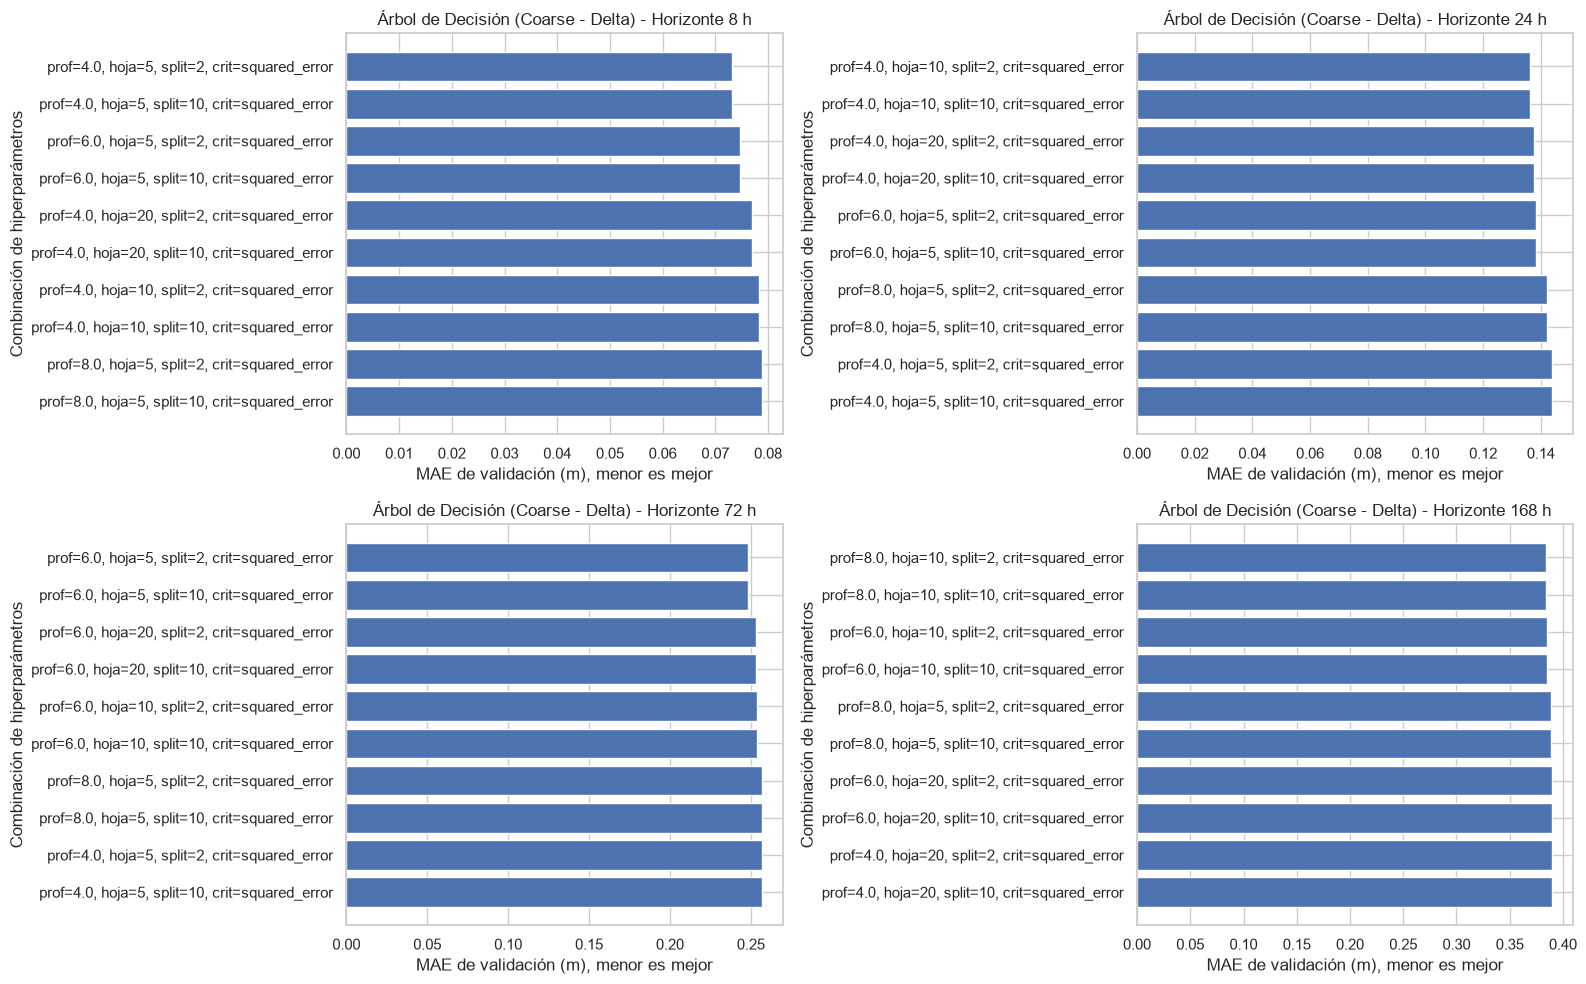

,modelo,horizonte_horas,muestras_prueba,MAE_m,RMSE_m
12,ridge_ajustado_pasado_delta,8,17845,0.114112,0.307988
0,persistencia_pura,8,17845,0.114439,0.309202
20,arbol_decision_ajustado_delta,8,17845,0.125855,0.274326
8,ridge_inicial_pasado_delta,8,17845,0.126933,0.271789
16,arbol_decision_inicial_delta,8,17845,0.131664,0.288915
1,persistencia_pasada_simetrica,8,17845,0.14802,0.345794
17,arbol_decision_inicial_delta,24,17876,0.198973,0.363703
9,ridge_inicial_pasado_delta,24,17876,0.203525,0.335592
21,arbol_decision_ajustado_delta,24,17876,0.204856,0.35722
3,persistencia_pasada_simetrica,24,17876,0.218702,0.393307


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

parametros_arbol = {
    "max_depth": [4, 6, 8, 10, 14, 18, None],
    "min_samples_leaf": [5, 10, 20, 50],
    "min_samples_split": [2, 10, 30],
    "criterion": ["squared_error", "absolute_error"],
}

resultados_busqueda_arbol = []
resultados_arbol_ajustado = []
modelos_arbol_ajustados = {}

for horizonte, particion in particiones_por_horizonte.items():
    entrenamiento = particion["entrenamiento"].copy()
    prueba = particion["prueba"].copy()
    columna_objetivo = f"maximo_observado_proximas_{horizonte}h"

    # 1. Creamos variables de velocidad/delta basadas en los picos pasados vs nivel actual
    for h_pasado in [8, 24, 72, 168]:
        entrenamiento[f"delta_pasado_{h_pasado}h"] = entrenamiento["nivel_t"] - entrenamiento[f"maximo_pasado_ultimas_{h_pasado}h"]
        prueba[f"delta_pasado_{h_pasado}h"] = prueba["nivel_t"] - prueba[f"maximo_pasado_ultimas_{h_pasado}h"]

    # Definimos los predictores completos
    predictores_completos = [
        "nivel_t",
        "mes_sin",
        "mes_cos",
        "maximo_pasado_ultimas_8h",
        "maximo_pasado_ultimas_24h",
        "maximo_pasado_ultimas_72h",
        "maximo_pasado_ultimas_168h",
        "delta_pasado_8h",
        "delta_pasado_24h",
        "delta_pasado_72h",
        "delta_pasado_168h",
    ]

    # 2. Transformamos el objetivo a DELTA
    y_entrenamiento_delta = entrenamiento[columna_objetivo] - entrenamiento["nivel_t"]
    y_prueba_real = prueba[columna_objetivo]

    busqueda = GridSearchCV(
        DecisionTreeRegressor(random_state=42),
        param_grid=parametros_arbol,
        scoring="neg_mean_absolute_error",
        cv=crear_pliegues_temporales(entrenamiento, horizonte),
        n_jobs=-1,
    )
    
    # 3. Ajustamos el GridSearch con los deltas y estacionalidad
    busqueda.fit(entrenamiento[predictores_completos], y_entrenamiento_delta)
    
    modelo = busqueda.best_estimator_
    modelos_arbol_ajustados[horizonte] = modelo

    # 4. Predecimos el delta y lo SUMAMOS al nivel_t actual de la prueba para volver a metros
    prediccion_delta = modelo.predict(prueba[predictores_completos])
    prediccion_nivel = prueba["nivel_t"] + prediccion_delta
    
    real = y_prueba_real

    for parametros, mae_cv in zip(
        busqueda.cv_results_["params"], -busqueda.cv_results_["mean_test_score"]
    ):
        resultados_busqueda_arbol.append({
            "horizonte_horas": horizonte,
            **parametros,
            "MAE_CV_m": mae_cv,
        })

    resultados_arbol_ajustado.append({
        "modelo": "arbol_decision_ajustado_delta",
        "horizonte_horas": horizonte,
        **busqueda.best_params_,
        "muestras_prueba": len(prueba),
        "MAE_CV_m": -busqueda.best_score_,
        "MAE_prueba_m": mean_absolute_error(real, prediccion_nivel),
        "RMSE_prueba_m": mean_squared_error(real, prediccion_nivel) ** 0.5,
    })

resultados_busqueda_arbol = pd.DataFrame(resultados_busqueda_arbol)
resultados_arbol_ajustado = pd.DataFrame(resultados_arbol_ajustado)

configuraciones_arbol_top = resultados_busqueda_arbol.copy()
configuraciones_arbol_top["configuracion"] = configuraciones_arbol_top.apply(
    lambda fila: (
        f"prof={fila['max_depth']}, hoja={fila['min_samples_leaf']}, "
        f"split={fila['min_samples_split']}, crit={fila['criterion']}"
    ),
    axis=1,
)

display(
    resultados_busqueda_arbol.sort_values(
        ["horizonte_horas", "MAE_CV_m"]
    ).groupby("horizonte_horas").head(5)
)
display(resultados_arbol_ajustado)

# Gráficas de validación
fig, ejes = plt.subplots(2, 2, figsize=(16, 10))
for eje, (horizonte, candidatos) in zip(
    ejes.flat, configuraciones_arbol_top.groupby("horizonte_horas")
):
    mejores = candidatos.nsmallest(10, "MAE_CV_m").sort_values("MAE_CV_m")
    eje.barh(mejores["configuracion"], mejores["MAE_CV_m"])
    eje.invert_yaxis()
    eje.set_title(f"Árbol de Decisión (Coarse - Delta) - Horizonte {horizonte} h")
    eje.set_xlabel("MAE de validación (m), menor es mejor")
    eje.set_ylabel("Combinación de hiperparámetros")

fig.tight_layout()
plt.show()

resultados_comparacion = pd.concat(
    [
        resultados_comparacion,
        resultados_arbol_ajustado.rename(columns={
            "MAE_prueba_m": "MAE_m",
            "RMSE_prueba_m": "RMSE_m",
        })[["modelo", "horizonte_horas", "muestras_prueba", "MAE_m", "RMSE_m"]],
    ],
    ignore_index=True,
)
display(resultados_comparacion.sort_values(["horizonte_horas", "MAE_m"]))

## 10. Bosque aleatorio (Random Forest)

### 10.1 Modelo inicial de Random Forest

Se entrena un ensamble de árboles mediante `RandomForestRegressor`. El ensamble promedia múltiples árboles entrenados sobre submuestras generadas mediante *bootstrap* y selección aleatoria de variables por división, reduciendo notablemente la varianza del estimador y amortiguando el sobreajuste.

La configuración base inicial utiliza hiperparámetros estables y robustos:
- `n_estimators = 100` (100 árboles)
- `max_depth = 16`
- `min_samples_leaf = 5`
- `random_state = 42`
- `n_jobs = -1`

Se entrena y evalúa en la partición independiente de prueba (20 %) para cada horizonte temporal.


In [131]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

resultados_random_forest_inicial = []
modelos_random_forest_iniciales = {}

for horizonte, particion in particiones_por_horizonte.items():
    entrenamiento = particion["entrenamiento"].copy()
    prueba = particion["prueba"].copy()
    col_objetivo_original = f"maximo_observado_proximas_{horizonte}h"

    # 1. Creamos variables de velocidad/delta basadas en los picos pasados vs nivel actual
    for h_pasado in [8, 24, 72, 168]:
        entrenamiento[f"delta_pasado_{h_pasado}h"] = entrenamiento["nivel_t"] - entrenamiento[f"maximo_pasado_ultimas_{h_pasado}h"]
        prueba[f"delta_pasado_{h_pasado}h"] = prueba["nivel_t"] - prueba[f"maximo_pasado_ultimas_{h_pasado}h"]

    # Definimos los predictores completos
    predictores_completos = [
        "nivel_t",
        "mes_sin",
        "mes_cos",
        "maximo_pasado_ultimas_8h",
        "maximo_pasado_ultimas_24h",
        "maximo_pasado_ultimas_72h",
        "maximo_pasado_ultimas_168h",
        "delta_pasado_8h",
        "delta_pasado_24h",
        "delta_pasado_72h",
        "delta_pasado_168h",
    ]

    # 2. Transformamos el objetivo a DELTA (Máximo futuro - Nivel actual en t)
    y_entrenamiento_delta = entrenamiento[col_objetivo_original] - entrenamiento["nivel_t"]
    y_prueba_real = prueba[col_objetivo_original]

    modelo = RandomForestRegressor(
        n_estimators=100,
        max_depth=16,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
    )
    
    # 3. Entrenamos con los predictores completos y el objetivo en delta
    modelo.fit(entrenamiento[predictores_completos], y_entrenamiento_delta)
    
    # 4. Predecimos el delta y lo SUMAMOS al nivel_t actual de la prueba para volver a metros
    prediccion_delta = modelo.predict(prueba[predictores_completos])
    prediccion_nivel = prueba["nivel_t"] + prediccion_delta
    
    modelos_random_forest_iniciales[horizonte] = modelo

    resultados_random_forest_inicial.append({
        "modelo": "random_forest_inicial_delta",
        "horizonte_horas": horizonte,
        "muestras_prueba": len(prueba),
        "MAE_m": mean_absolute_error(y_prueba_real, prediccion_nivel),
        "RMSE_m": mean_squared_error(y_prueba_real, prediccion_nivel) ** 0.5,
    })

resultados_random_forest_inicial = pd.DataFrame(resultados_random_forest_inicial)
display(resultados_random_forest_inicial)

resultados_comparacion = pd.concat(
    [
        resultados_comparacion,
        resultados_random_forest_inicial[["modelo", "horizonte_horas", "muestras_prueba", "MAE_m", "RMSE_m"]],
    ],
    ignore_index=True,
)
display(resultados_comparacion.sort_values(["horizonte_horas", "MAE_m"]))

,modelo,horizonte_horas,muestras_prueba,MAE_m,RMSE_m
0,random_forest_inicial_delta,8,17845,0.136178,0.279718
1,random_forest_inicial_delta,24,17876,0.209849,0.354917
2,random_forest_inicial_delta,72,17885,0.317330,0.444378
3,random_forest_inicial_delta,168,17888,0.428702,0.563700


,modelo,horizonte_horas,muestras_prueba,MAE_m,RMSE_m
12,ridge_ajustado_pasado_delta,8,17845,0.114112,0.307988
0,persistencia_pura,8,17845,0.114439,0.309202
20,arbol_decision_ajustado_delta,8,17845,0.125855,0.274326
8,ridge_inicial_pasado_delta,8,17845,0.126933,0.271789
16,arbol_decision_inicial_delta,8,17845,0.131664,0.288915
24,random_forest_inicial_delta,8,17845,0.136178,0.279718
1,persistencia_pasada_simetrica,8,17845,0.14802,0.345794
17,arbol_decision_inicial_delta,24,17876,0.198973,0.363703
9,ridge_inicial_pasado_delta,24,17876,0.203525,0.335592
21,arbol_decision_ajustado_delta,24,17876,0.204856,0.35722


### 10.2 Búsqueda de hiperparámetros de Random Forest (Fase Coarse - GridSearchCV)

Siguiendo la estrategia **Coarse-to-Fine**, en esta primera fase se diseña una exploración amplia que explora representativamente el espacio de búsqueda sin exceder el presupuesto computacional (calibrada para completarse en **~6 a 9 minutos** en procesadores modernos multihilo como el Core i5-12500).

Se evalúan **120 combinaciones por horizonte** (3 pliegues temporales = 360 ajustes de bosque por horizonte, 1.440 ajustes en total):
- `n_estimators`: `[60, 120]` (evalúa si una densidad intermedia de árboles es suficiente o si requiere mayor agregación).
- `max_depth`: `[6, 10, 14, 18, None]` (amplio espectro desde profundidad moderada hasta divisiones completas).
- `min_samples_leaf`: `[2, 5, 15, 30]` (evalúa la sensibilidad de ajuste fino vs. generalización robusta).
- `max_features`: `["sqrt", 0.6, 1.0]` (explora descorrelación estricta $\approx 3$ variables, subespacio intermedio $\approx 7$ variables, y todas las 11 variables).

La búsqueda se ejecuta con los pliegues temporales purgados (`crear_pliegues_temporales`) y selección por MAE (`neg_mean_absolute_error`). Tras la ejecución, se visualizarán las mejores regiones para la subsecuente fase de afinamiento fino.


,horizonte_horas,max_depth,max_features,min_samples_leaf,n_estimators,MAE_CV_m
6,8,6.0,sqrt,30,60,0.068851
14,8,6.0,0.6,30,60,0.068987
15,8,6.0,0.6,30,120,0.069080
22,8,6.0,1.0,30,60,0.069095
7,8,6.0,sqrt,30,120,0.069161
143,24,6.0,1.0,30,120,0.129774
142,24,6.0,1.0,30,60,0.130015
135,24,6.0,0.6,30,120,0.130927
127,24,6.0,sqrt,30,120,0.131326
134,24,6.0,0.6,30,60,0.131447


,modelo,horizonte_horas,max_depth,max_features,min_samples_leaf,n_estimators,muestras_prueba,MAE_CV_m,MAE_prueba_m,RMSE_prueba_m
0,random_forest_ajustado_delta,8,6,sqrt,30,60,17845,0.068851,0.126517,0.266187
1,random_forest_ajustado_delta,24,6,1.0,30,120,17876,0.129774,0.193659,0.329265
2,random_forest_ajustado_delta,72,6,0.6,5,60,17885,0.225758,0.213794,0.316185
3,random_forest_ajustado_delta,168,6,sqrt,30,120,17888,0.355200,0.276644,0.360355


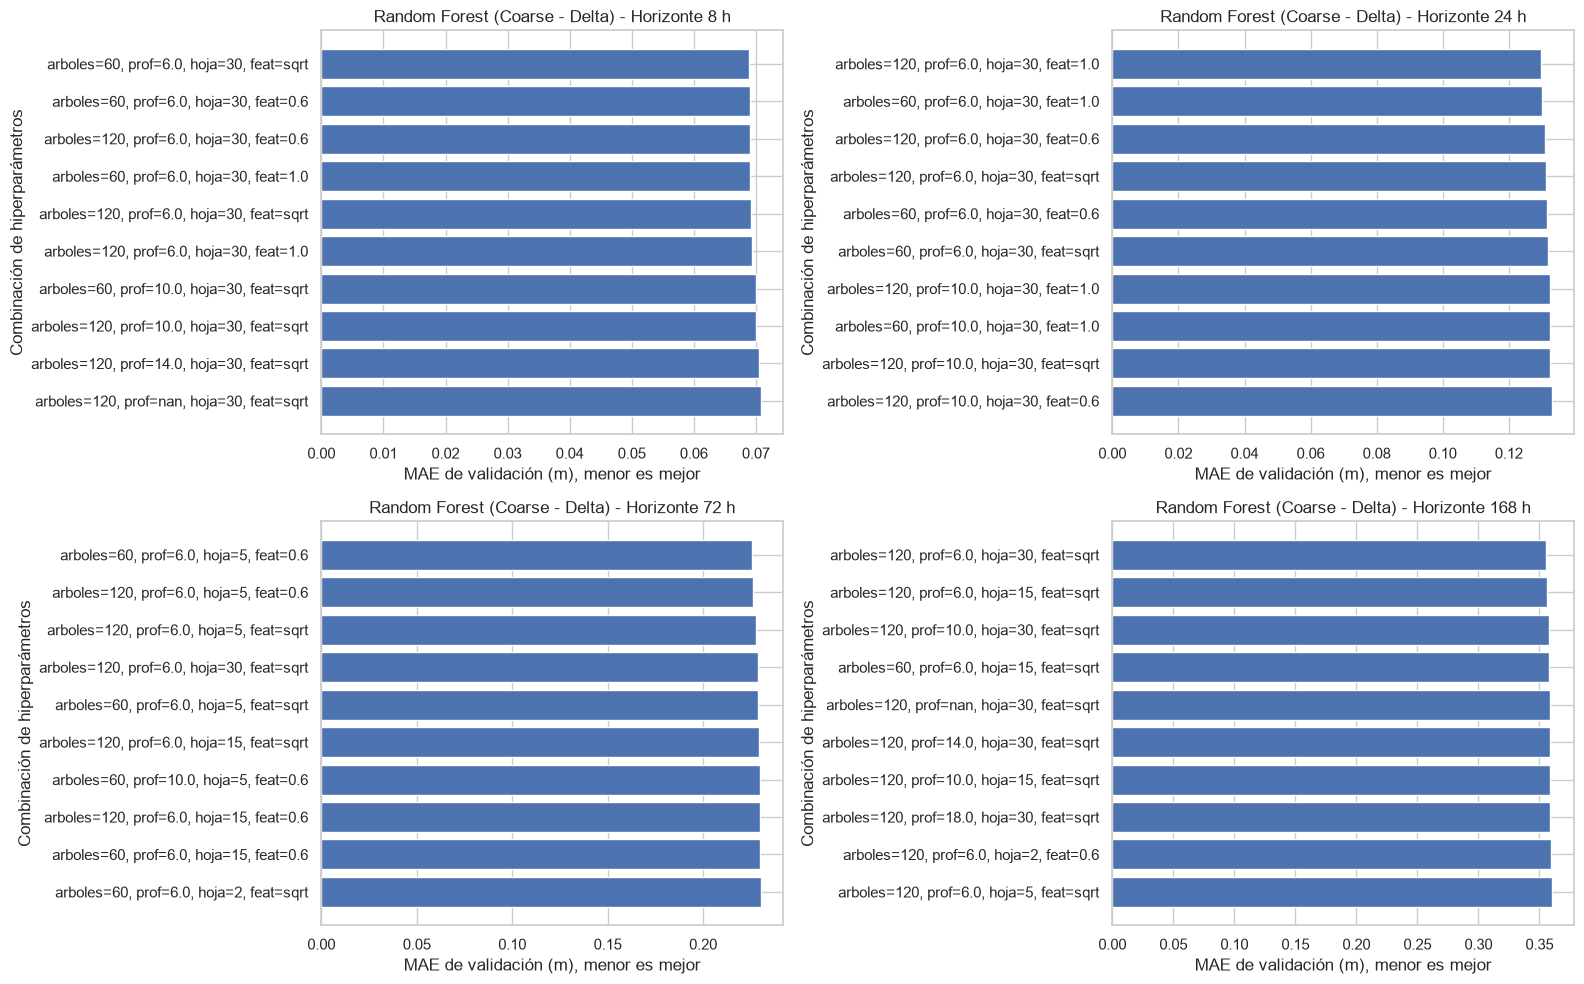

,modelo,horizonte_horas,muestras_prueba,MAE_m,RMSE_m
12,ridge_ajustado_pasado_delta,8,17845,0.114112,0.307988
0,persistencia_pura,8,17845,0.114439,0.309202
20,arbol_decision_ajustado_delta,8,17845,0.125855,0.274326
28,random_forest_ajustado_delta,8,17845,0.126517,0.266187
8,ridge_inicial_pasado_delta,8,17845,0.126933,0.271789
16,arbol_decision_inicial_delta,8,17845,0.131664,0.288915
24,random_forest_inicial_delta,8,17845,0.136178,0.279718
1,persistencia_pasada_simetrica,8,17845,0.14802,0.345794
29,random_forest_ajustado_delta,24,17876,0.193659,0.329265
17,arbol_decision_inicial_delta,24,17876,0.198973,0.363703


In [132]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error

parametros_random_forest = {
    "n_estimators": [60, 120],
    "max_depth": [6, 10, 14, 18, None],
    "min_samples_leaf": [2, 5, 15, 30],
    "max_features": ["sqrt", 0.6, 1.0],
}

resultados_busqueda_random_forest = []
resultados_random_forest_ajustado = []
modelos_random_forest_ajustados = {}

for horizonte, particion in particiones_por_horizonte.items():
    entrenamiento = particion["entrenamiento"].copy()
    prueba = particion["prueba"].copy()
    columna_objetivo = f"maximo_observado_proximas_{horizonte}h"

    # 1. Creamos variables de velocidad/delta basadas en los picos pasados vs nivel actual
    for h_pasado in [8, 24, 72, 168]:
        entrenamiento[f"delta_pasado_{h_pasado}h"] = entrenamiento["nivel_t"] - entrenamiento[f"maximo_pasado_ultimas_{h_pasado}h"]
        prueba[f"delta_pasado_{h_pasado}h"] = prueba["nivel_t"] - prueba[f"maximo_pasado_ultimas_{h_pasado}h"]

    # Definimos los predictores completos
    predictores_completos = [
        "nivel_t",
        "mes_sin",
        "mes_cos",
        "maximo_pasado_ultimas_8h",
        "maximo_pasado_ultimas_24h",
        "maximo_pasado_ultimas_72h",
        "maximo_pasado_ultimas_168h",
        "delta_pasado_8h",
        "delta_pasado_24h",
        "delta_pasado_72h",
        "delta_pasado_168h",
    ]

    # 2. Transformamos el objetivo a DELTA
    y_entrenamiento_delta = entrenamiento[columna_objetivo] - entrenamiento["nivel_t"]
    y_prueba_real = prueba[columna_objetivo]

    busqueda = GridSearchCV(
        RandomForestRegressor(random_state=42, n_jobs=1),
        param_grid=parametros_random_forest,
        scoring="neg_mean_absolute_error",
        cv=crear_pliegues_temporales(entrenamiento, horizonte),
        n_jobs=-1,
    )
    
    # 3. Ajustamos el GridSearch con los predictores completos y el objetivo en delta
    busqueda.fit(entrenamiento[predictores_completos], y_entrenamiento_delta)
    
    modelo = busqueda.best_estimator_
    modelos_random_forest_ajustados[horizonte] = modelo

    # 4. Predecimos el delta y lo SUMAMOS al nivel_t actual de la prueba para volver a metros
    prediccion_delta = modelo.predict(prueba[predictores_completos])
    prediccion_nivel = prueba["nivel_t"] + prediccion_delta
    
    real = y_prueba_real

    for parametros, mae_cv in zip(
        busqueda.cv_results_["params"], -busqueda.cv_results_["mean_test_score"]
    ):
        resultados_busqueda_random_forest.append({
            "horizonte_horas": horizonte,
            **parametros,
            "MAE_CV_m": mae_cv,
        })

    resultados_random_forest_ajustado.append({
        "modelo": "random_forest_ajustado_delta",
        "horizonte_horas": horizonte,
        **busqueda.best_params_,
        "muestras_prueba": len(prueba),
        "MAE_CV_m": -busqueda.best_score_,
        "MAE_prueba_m": mean_absolute_error(real, prediccion_nivel),
        "RMSE_prueba_m": mean_squared_error(real, prediccion_nivel) ** 0.5,
    })

resultados_busqueda_random_forest = pd.DataFrame(
    resultados_busqueda_random_forest
)
resultados_random_forest_ajustado = pd.DataFrame(
    resultados_random_forest_ajustado
)

configuraciones_random_forest_top = resultados_busqueda_random_forest.copy()
configuraciones_random_forest_top["configuracion"] = (
    configuraciones_random_forest_top.apply(
        lambda fila: (
            f"arboles={fila['n_estimators']}, prof={fila['max_depth']}, "
            f"hoja={fila['min_samples_leaf']}, feat={fila['max_features']}"
        ),
        axis=1,
    )
)

display(
    resultados_busqueda_random_forest.sort_values(
        ["horizonte_horas", "MAE_CV_m"]
    ).groupby("horizonte_horas").head(5)
)
display(resultados_random_forest_ajustado)

# Gráficas de validación
fig, ejes = plt.subplots(2, 2, figsize=(16, 10))
for eje, (horizonte, candidatos) in zip(
    ejes.flat, configuraciones_random_forest_top.groupby("horizonte_horas")
):
    mejores = candidatos.nsmallest(10, "MAE_CV_m").sort_values("MAE_CV_m")
    eje.barh(mejores["configuracion"], mejores["MAE_CV_m"])
    eje.invert_yaxis()
    eje.set_title(f"Random Forest (Coarse - Delta) - Horizonte {horizonte} h")
    eje.set_xlabel("MAE de validación (m), menor es mejor")
    eje.set_ylabel("Combinación de hiperparámetros")

fig.tight_layout()
plt.show()

resultados_comparacion = pd.concat(
    [
        resultados_comparacion,
        resultados_random_forest_ajustado.rename(columns={
            "MAE_prueba_m": "MAE_m",
            "RMSE_prueba_m": "RMSE_m",
        })[["modelo", "horizonte_horas", "muestras_prueba", "MAE_m", "RMSE_m"]],
    ],
    ignore_index=True,
)
display(resultados_comparacion.sort_values(["horizonte_horas", "MAE_m"]))

## 11. Comparación general y consolidación de modelos

Esta sección consolida las métricas de prueba de todas las aproximaciones evaluadas:
- **Líneas base heurísticas**: `ultimo_nivel`, `maximo_pasado_mismo_horizonte`.
- **Modelos iniciales**: `ridge_inicial`, `arbol_decision_inicial`, `random_forest_inicial`.
- **Modelos optimizados (GridSearchCV)**: `ridge_ajustado`, `arbol_decision_ajustado`, `random_forest_ajustado`.

A continuación, se presenta la tabla general clasificada por horizonte de pronóstico y MAE, junto con un gráfico comparativo del error medio absoluto (MAE) en función del horizonte temporal.


,modelo,horizonte_horas,muestras_prueba,MAE_m,RMSE_m
0,ridge_ajustado_pasado_delta,8,17845,0.114112,0.307988
1,persistencia_pura,8,17845,0.114439,0.309202
2,arbol_decision_ajustado_delta,8,17845,0.125855,0.274326
3,random_forest_ajustado_delta,8,17845,0.126517,0.266187
4,ridge_inicial_pasado_delta,8,17845,0.126933,0.271789
5,arbol_decision_inicial_delta,8,17845,0.131664,0.288915
6,random_forest_inicial_delta,8,17845,0.136178,0.279718
7,persistencia_pasada_simetrica,8,17845,0.14802,0.345794
8,random_forest_ajustado_delta,24,17876,0.193659,0.329265
9,arbol_decision_inicial_delta,24,17876,0.198973,0.363703


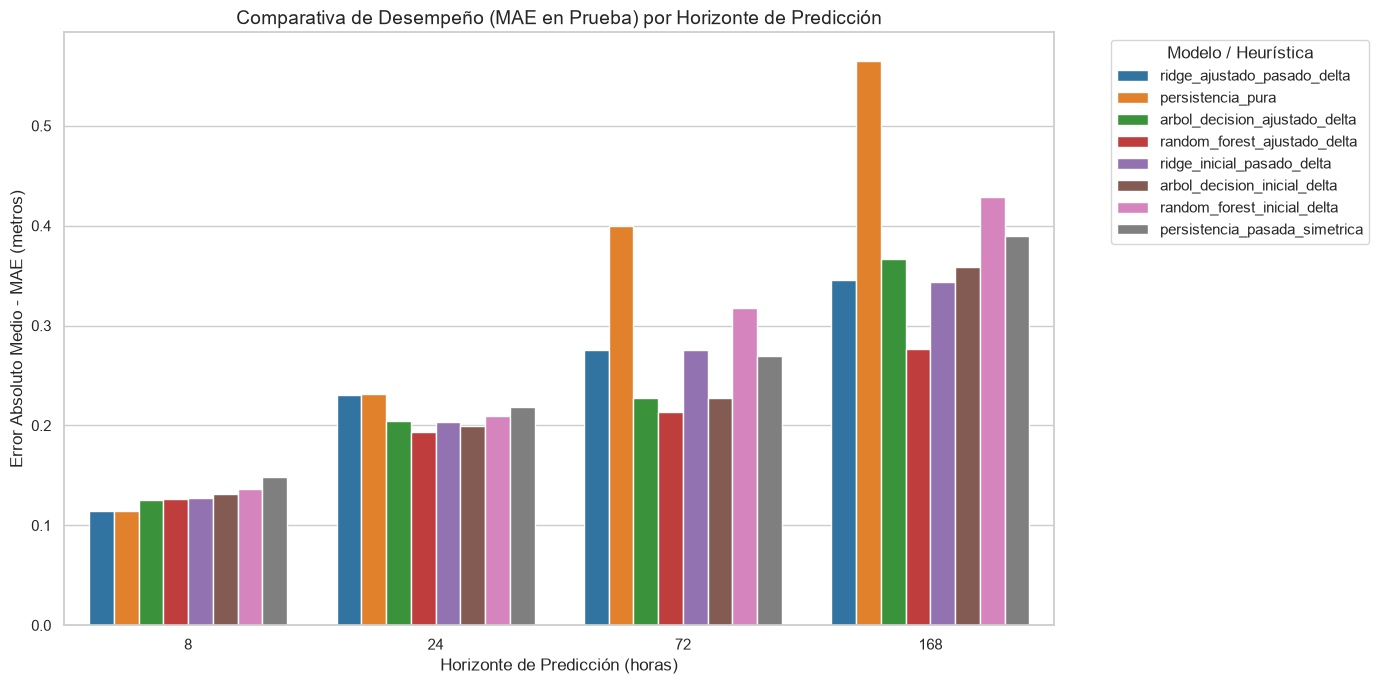

In [133]:
# Tabla consolidada ordenada por horizonte y desempeño (menor MAE)
tabla_final = resultados_comparacion.sort_values(
    ["horizonte_horas", "MAE_m"]
).reset_index(drop=True)
display(tabla_final)

# Gráfico comparativo de MAE por horizonte entre todos los modelos evaluados
plt.figure(figsize=(14, 7))
sns.barplot(
    data=tabla_final,
    x="horizonte_horas",
    y="MAE_m",
    hue="modelo",
    palette="tab10",
)
plt.title("Comparativa de Desempeño (MAE en Prueba) por Horizonte de Predicción", fontsize=14)
plt.xlabel("Horizonte de Predicción (horas)", fontsize=12)
plt.ylabel("Error Absoluto Medio - MAE (metros)", fontsize=12)
plt.legend(title="Modelo / Heurística", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()
